<a href="https://colab.research.google.com/github/Avani0910/DSIP_104_Avani_Kavathiya/blob/main/Experiment10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

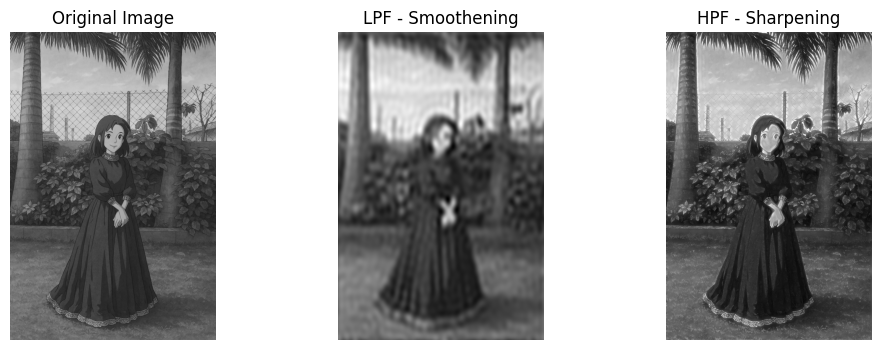

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Read image using image path
img = cv2.imread('/content/Avani.jpg', 0)

# 2. Fourier Transform
F = np.fft.fftshift(np.fft.fft2(img))
M, N = img.shape

# 3. Create frequency distance matrix
u, v = np.meshgrid(np.arange(N)-N//2, np.arange(M)-M//2)
D = np.sqrt(u**2 + v**2)

# 4. Low-Pass and High-Pass Filters
LPF = D < 30
HPF = D >= 30

# 5. Apply filters
smooth = np.abs(np.fft.ifft2(np.fft.ifftshift(F * LPF)))
high_pass = np.abs(np.fft.ifft2(np.fft.ifftshift(F * HPF)))
sharp = np.clip(img.astype(float) + high_pass, 0, 255)

# 6. Display images
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')

plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(smooth, cmap='gray')
plt.title('LPF - Smoothening')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(sharp, cmap='gray')
plt.title('HPF - Sharpening')
plt.axis('off')

plt.show()